# PBL-I Project Review — Machine Learning (21CSC305P), Unit 1 & Unit 2
## Group 4: Used Car Price Prediction and Condition Classification

**Course:** 21CSC305P — Machine Learning &nbsp;|&nbsp; **Portion:** Unit 1 & Unit 2 &nbsp;|&nbsp; **Total:** 20 Marks

**Project problem (assigned brief):** Develop an ML system to predict the resale price of used
cars and classify vehicles according to their condition/value category.

**Dataset:** `Group_4_Dataset.csv` — 8,128 used-car listings (CarDekho-style), 13 raw columns:
`name, year, selling_price, km_driven, fuel, seller_type, transmission, owner, mileage, engine,
max_power, torque, seats`.

This notebook answers Q1–Q5 of the PBL-I review format, 4 marks each, and is runnable top to bottom.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('src'))
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from IPython.display import display, Image

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)


---
## Q1. Problem Identification & Dataset Selection — 4 Marks

**Real-world problem.** Used-car marketplaces need to (a) quote a fair resale price for a
listed vehicle and (b) bucket it into a value tier a buyer can filter by. Both are decisions a
seller/platform currently makes manually or with rough rules of thumb; an ML system can do it
consistently from the vehicle's own attributes.

**ML objective.**
- **Regression task:** predict `selling_price` (continuous, INR) from vehicle attributes.
- **Classification task:** predict a **price tier — Budget / Mid / Premium** — a discretisation
  of the same target, standing in for "condition/value category" since the raw data has no
  separate condition field. Tier cut points are the 33rd/67th percentile of price, **fit on the
  training split only** (see Q3) so no test information leaks into the label definition.

**Input features (both tasks):** `car_age` (derived from `year`), `km_driven`, `mileage`,
`engine`, `max_power`, `torque_nm`, `torque_rpm`, `seats` (numeric) and `brand` (derived from
`name`), `fuel`, `seller_type`, `transmission`, `owner` (categorical). `selling_price` is the
regression target and is **excluded from the classifier's features** — predicting a
price-derived label from the price itself would be circular.

**Regression target:** `selling_price` (modelled as `log(selling_price)` — see Q2 for why).
**Classification target:** `price_tier` ∈ {Budget, Mid, Premium}.

**Dataset justification.** 8,128 rows spans 32 brands, model years 1983–2020, and both fuel/
transmission/ownership categories with enough support per level for stratified learning
(the rarest class, `owner = Test Drive Car`, still has 5 rows). It directly matches the brief's
suggested data ("year, mileage, engine size, fuel type, transmission, price, etc.") and is the
right size for the four regression + three classification models used in Q3 without needing a
larger external source.


In [2]:
raw = pd.read_csv('Group_4_Dataset.csv')
print(f"Raw shape: {raw.shape}")
display(raw.head())
raw.dtypes


Raw shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


name                 str
year               int64
selling_price      int64
km_driven          int64
fuel                 str
seller_type          str
transmission         str
owner                str
mileage              str
engine               str
max_power            str
torque               str
seats            float64
dtype: object

---
## Q2. Exploratory Data Analysis & Insights — 4 Marks

### 2.1 Cleaning pipeline

The raw data needs unit-stripping (`mileage`, `engine`, `max_power` carry text suffixes;
`torque` is free text in 6+ formats), duplicate removal, and missing-value handling before any
statistics are meaningful. `src/data_prep.py` implements this; the key steps, in order:

1. **Drop exact duplicate rows** (1,202 of 8,128) — *before* anything else, so duplicates can
   never straddle a later train/test split and inflate metrics.
2. Strip units (`kmpl`/`km/kg` → float, `CC` → float, `bhp` → float); a handful of `max_power="0"`
   and `mileage="0"` readings on non-electric cars are undisclosed values, not real zeros → NaN.
3. Parse `torque`'s many text formats into `torque_nm` + `torque_rpm`, resolving the Nm-vs-kgm
   ambiguity correctly (see code comments in `_parse_torque` — one format tags every value
   `"(kgm@ rpm)"` regardless of true unit; a clear bimodal gap in the value distribution
   separates genuine kgm readings from already-Nm ones mislabelled by the same template).
   A few residual physically-impossible readings (e.g. a 58 bhp engine "producing" 789 Nm) are
   caught by a plausibility range and treated as missing.
4. Drop the 208 rows with **no** spec data at all; median-impute the small residual NaN count.
5. Feature-engineer `brand` (first word of `name`, cuts cardinality from 2,058 to 32) and
   `car_age = 2020 - year`.

**Final cleaned dataset: 6,718 rows, 0 missing values.**


In [3]:
from data_prep import load_clean
df = load_clean()
print(f"\nCleaned shape: {df.shape}")
display(df.head())


Raw rows:                8128
After exact dedupe:      6926  (-1202)
Dropped (no spec data):  208
Implausible torque/rpm readings -> NaN'd: 4
Final cleaned rows:      6718

Residual NaNs before median-impute (per column):
mileage       15
engine         0
max_power      1
torque_nm      4
seats          0
torque_rpm     6

km_driven q99 cap used for modelling: 239,907 km

Cleaned shape: (6718, 16)


,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,torque_nm,torque_rpm,brand,car_age,km_driven_capped
0,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,190.000000,2000.0,Maruti,6,145500.0
1,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,250.000000,2500.0,Skoda,6,120000.0
2,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,124.544455,2700.0,Honda,14,140000.0
3,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,219.668960,2750.0,Hyundai,10,127000.0
4,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,112.776475,4500.0,Maruti,13,120000.0


### 2.2 Missing values (raw dataset)


In [4]:
from eda import missing_value_report
mv = missing_value_report()
display(mv[mv['missing_count'] > 0])


,missing_count,missing_pct
torque,222,2.73
seats,221,2.72
engine,221,2.72
mileage,221,2.72
max_power,215,2.65


### 2.3 Descriptive statistics — mean, variance/std, quantiles (cleaned data)


In [5]:
from eda import descriptive_stats, NUMERIC_COLS
stats = descriptive_stats(df)
display(stats)


,mean,std,var,min,q25,median,q75,q95,max
selling_price,526319.551,523539.803,2.740939e+11,29999.000,250000.0,420000.00,650000.000,1200000.00,10000000.0
km_driven,73402.297,58699.803,3.445667e+09,1.000,38000.0,68221.50,100000.000,155000.00,2360457.0
car_age,6.391,3.901,1.521500e+01,0.000,3.0,6.00,9.000,13.00,26.0
mileage,19.509,3.943,1.554800e+01,9.000,16.8,19.49,22.500,25.83,42.0
engine,1430.891,493.493,2.435356e+05,624.000,1197.0,1248.00,1498.000,2499.00,3604.0
max_power,87.765,31.722,1.006303e+03,32.800,67.1,81.83,100.000,147.90,400.0
torque_nm,170.672,83.564,6.982916e+03,47.072,110.0,160.00,200.056,330.00,640.0
torque_rpm,3044.489,888.588,7.895886e+05,1400.000,2250.0,3000.00,4000.000,4500.00,5300.0
seats,5.435,0.984,9.690000e-01,2.000,5.0,5.00,5.000,7.00,14.0


### 2.4 Correlation & covariance


In [6]:
corr = df[NUMERIC_COLS].corr()
display(corr.round(3))
print("\nCorrelation with selling_price, sorted:")
display(corr['selling_price'].sort_values(ascending=False).round(3))


,selling_price,km_driven,car_age,mileage,engine,max_power,torque_nm,torque_rpm,seats
selling_price,1.000,-0.161,-0.427,-0.108,0.443,0.692,0.638,-0.091,0.158
km_driven,-0.161,1.000,0.388,-0.204,0.253,0.042,0.151,-0.227,0.208
car_age,-0.427,0.388,1.000,-0.373,0.019,-0.160,-0.144,-0.065,-0.024
mileage,-0.108,-0.204,-0.373,1.000,-0.591,-0.389,-0.255,-0.185,-0.481
engine,0.443,0.253,0.019,-0.591,1.000,0.683,0.753,-0.262,0.658
max_power,0.692,0.042,-0.160,-0.389,0.683,1.000,0.853,-0.023,0.259
torque_nm,0.638,0.151,-0.144,-0.255,0.753,0.853,1.000,-0.451,0.393
torque_rpm,-0.091,-0.227,-0.065,-0.185,-0.262,-0.023,-0.451,1.000,-0.220
seats,0.158,0.208,-0.024,-0.481,0.658,0.259,0.393,-0.220,1.000



Correlation with selling_price, sorted:


selling_price    1.000
max_power        0.692
torque_nm        0.638
engine           0.443
seats            0.158
torque_rpm      -0.091
mileage         -0.108
km_driven       -0.161
car_age         -0.427
Name: selling_price, dtype: float64

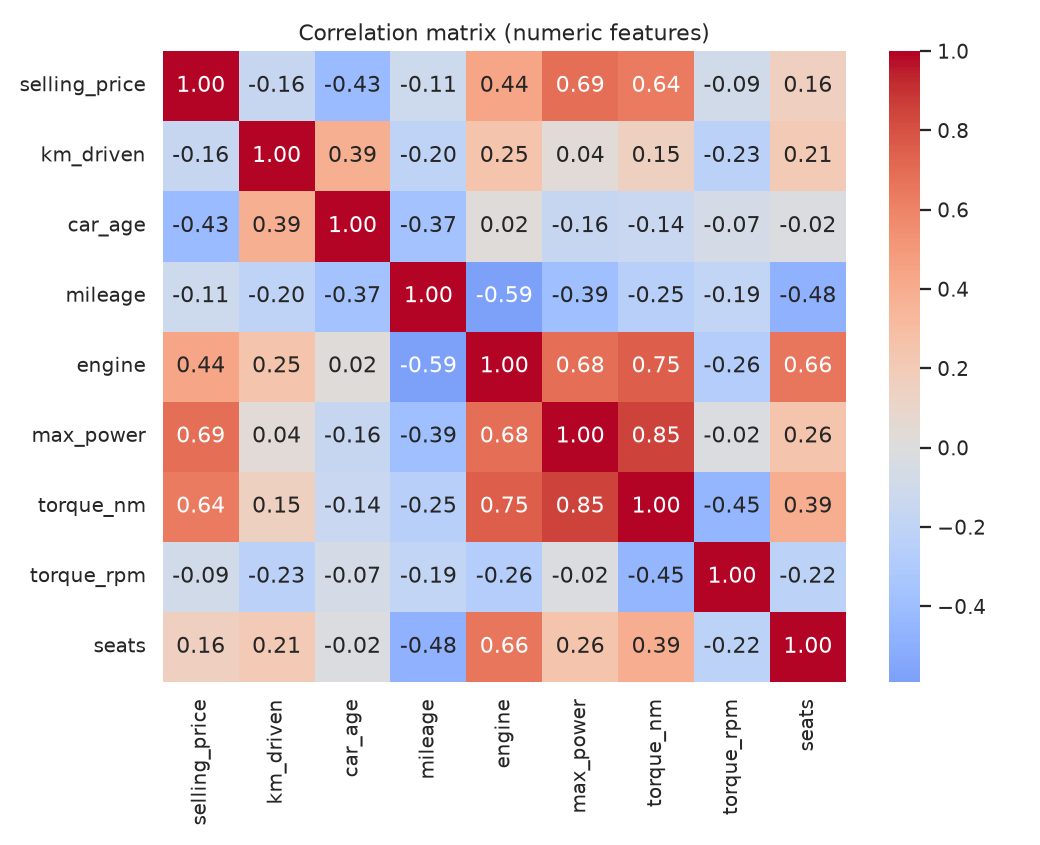

In [7]:
display(Image(filename='outputs/figures/correlation_heatmap.png'))


### 2.5 Distributions


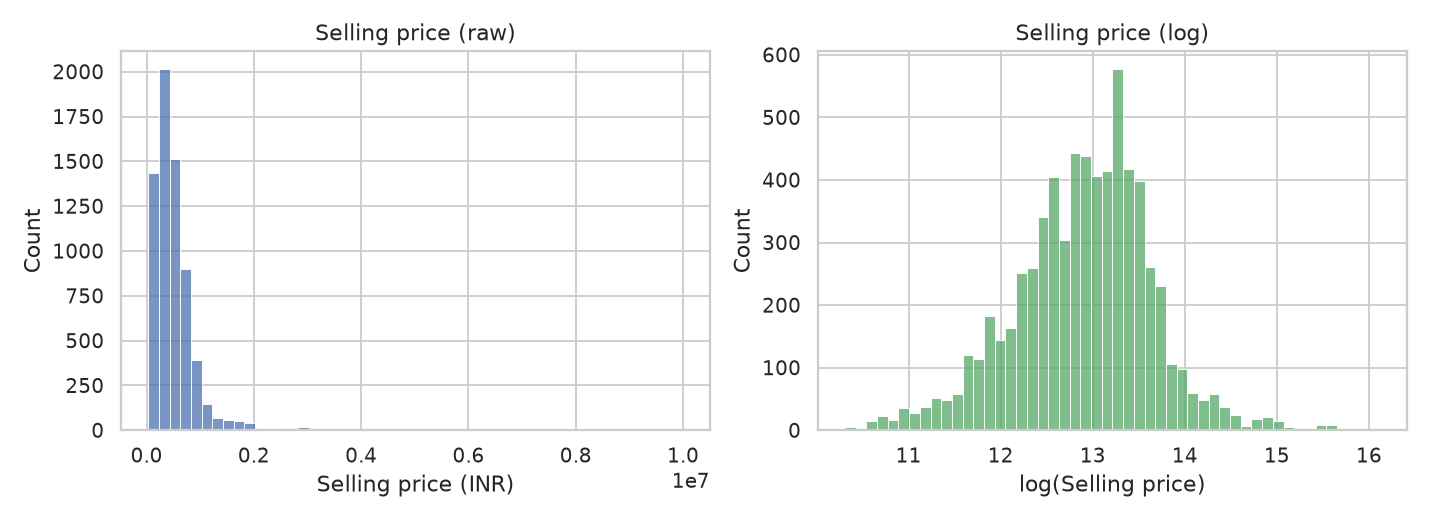

In [8]:
display(Image(filename='outputs/figures/price_distribution.png'))


`selling_price` is strongly right-skewed (mean ≫ median tail past INR 20L); the log transform
on the right makes it roughly symmetric, which is why regression targets `log(selling_price)`.


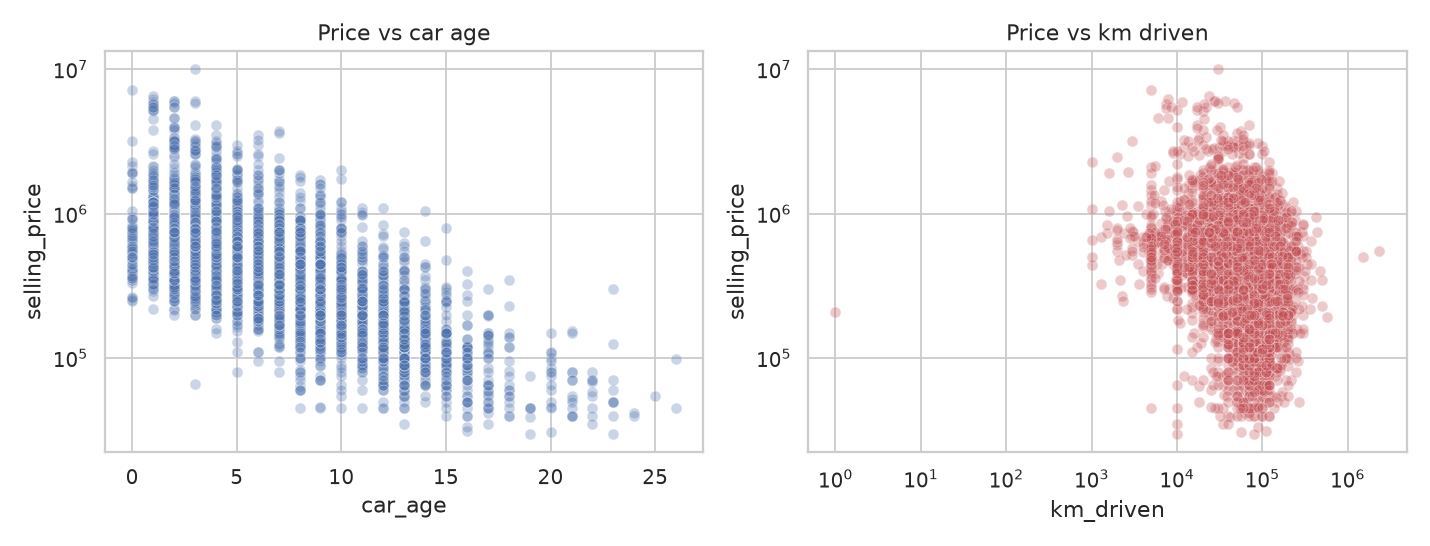

In [9]:
display(Image(filename='outputs/figures/price_vs_age_km.png'))


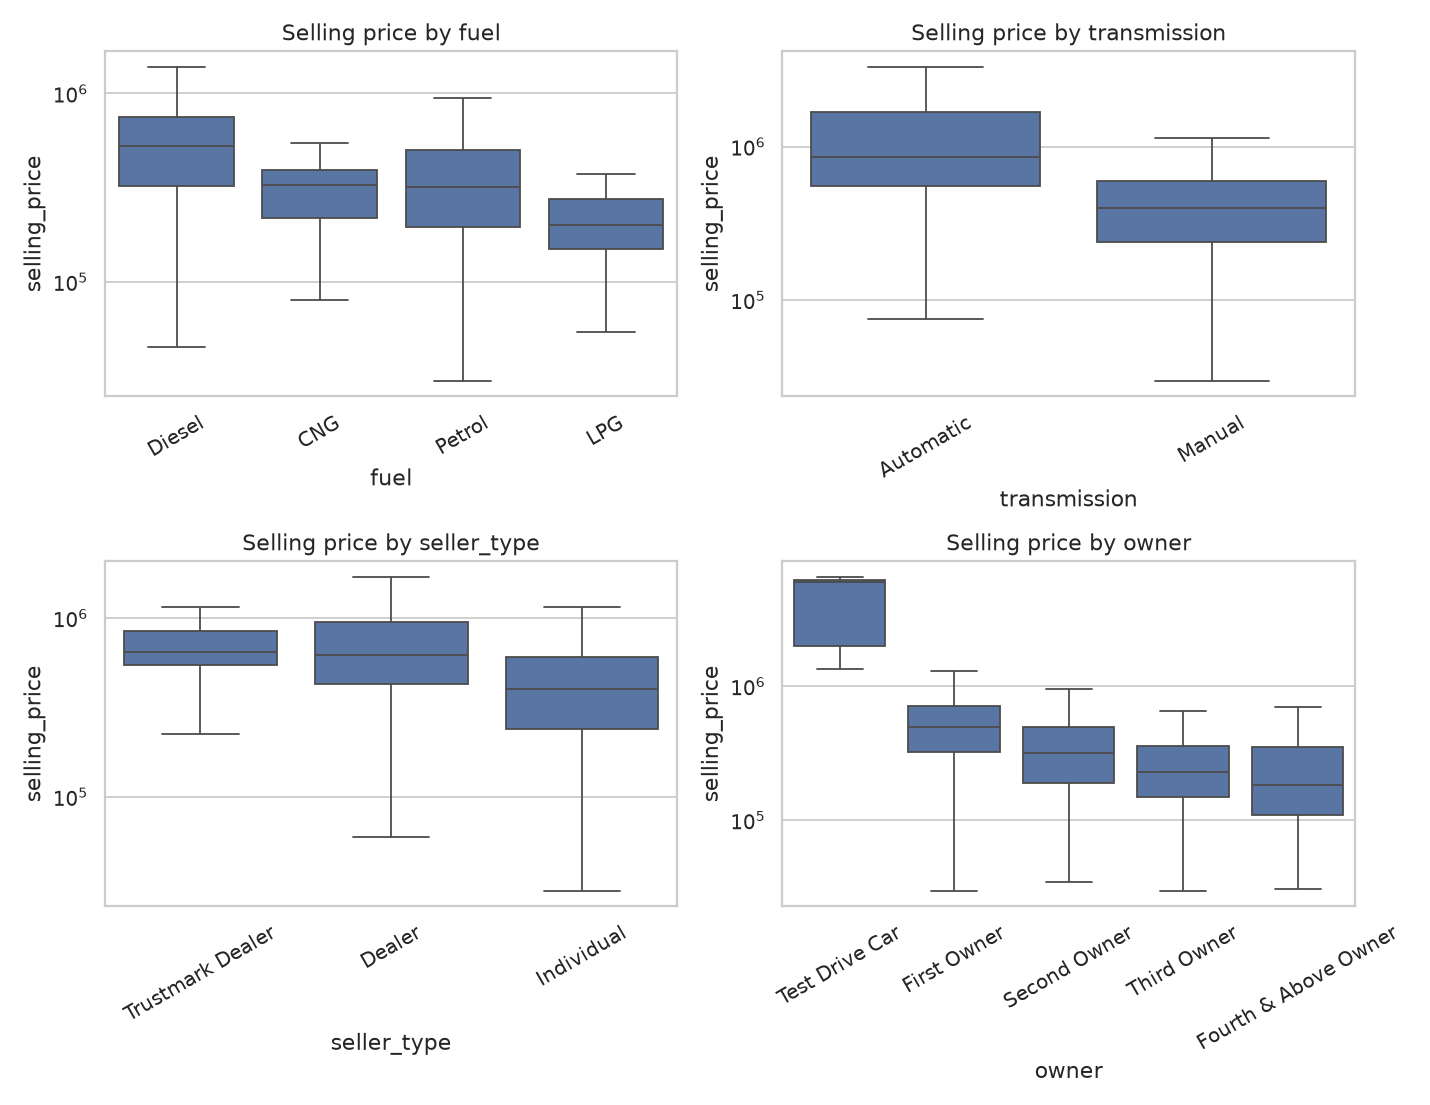

In [10]:
display(Image(filename='outputs/figures/price_by_category.png'))


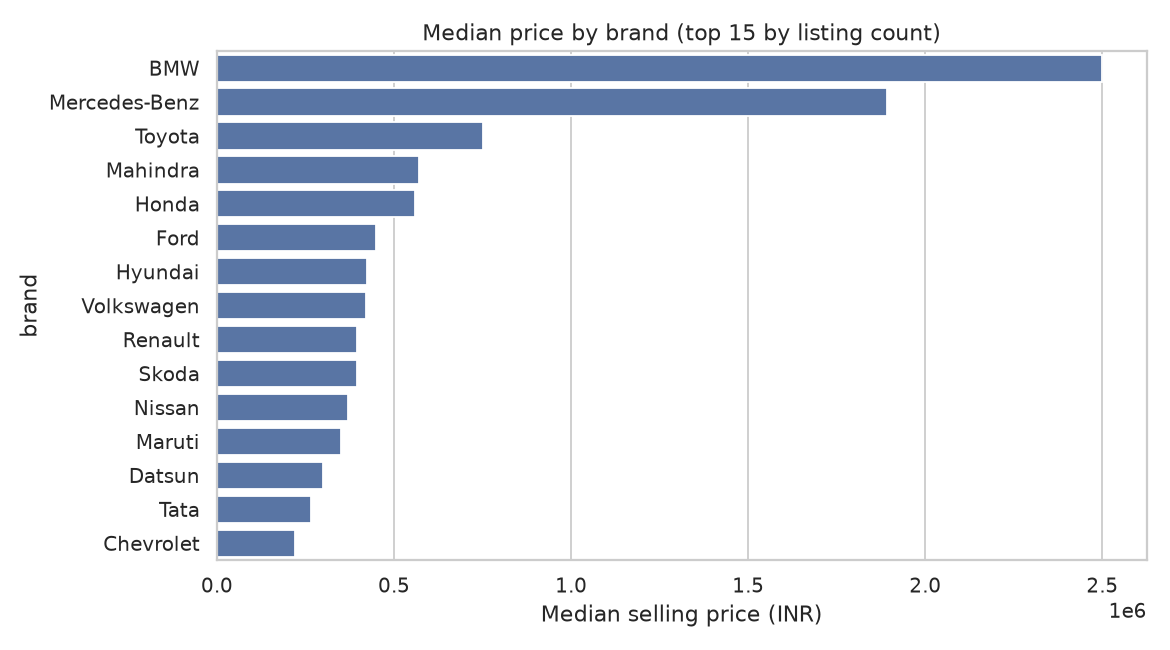

In [11]:
display(Image(filename='outputs/figures/brand_median_price.png'))


### 2.6 Outlier detection (IQR rule)


In [12]:
from eda import outlier_summary
outliers = outlier_summary(df)
display(outliers)


,column,lower_fence,upper_fence,n_outliers,pct_outliers
0,selling_price,-350000.00,1250000.00,306,4.55
1,km_driven,-55000.00,193000.00,161,2.40
2,car_age,-6.00,18.00,57,0.85
3,mileage,8.25,31.05,6,0.09
4,engine,745.50,1949.50,1207,17.97
5,max_power,17.75,149.35,304,4.53
6,torque_nm,-25.08,335.14,282,4.20
7,torque_rpm,-375.00,6625.00,0,0.00
8,seats,5.00,5.00,1464,21.79


`seats` and `engine` show the highest outlier rates by the strict 1.5×IQR rule, but both are
genuinely multi-modal (5/7/8-seaters; small/mid/large engines) rather than data errors — the
rule flags legitimate minority body types, not bad data. `selling_price` and `km_driven` outliers
are real high-end/high-mileage listings and are kept (capped only for `km_driven` at the 99th
percentile for modelling stability — see `km_driven_capped`).

### 2.7 Key insights
1. **Price is right-skewed** (mean INR 5.26L vs median INR 4.2L, max INR 1Cr) → modelled in log
   space for regression.
2. **`car_age` and `km_driven` are the strongest negative correlates of price** (−0.43, −0.16);
   `max_power` and `torque_nm` are the strongest positive ones (+0.69, +0.64) — depreciation and
   engine output dominate resale value, matching real-world intuition.
3. **Automatic-transmission and Diesel-fuel listings carry a materially higher median price**
   than Manual/Petrol — a segment effect (automatics skew premium) compounding a fuel-cost effect.
4. **`max_power`, `engine` and `torque_nm` are highly collinear** (r ≈ 0.68–0.85, all describing
   engine output) — motivating Ridge/Bayesian regularisation over plain OLS in Q3.


---
## Q3. Regression & Classification Implementation — 4 Marks

**Preprocessing (shared):** `StandardScaler` on numeric features, `OneHotEncoder(drop='first',
handle_unknown='ignore')` on categoricals, assembled in a `ColumnTransformer` so scaling/encoding
is always fit on the training fold only (no leakage). Polynomial Regression additionally expands
**only the numeric block** to degree 2 before the categorical one-hot columns are concatenated —
expanding the 32-level `brand` dummy set too would blow up the feature matrix for no benefit.

**Train/test split:** a single 80/20 split (`random_state=42`), stratified on a rough price bin,
is computed once in `src/split.py` and reused identically for both tasks (`src/regression.py`,
`src/classification.py`) so Q4's comparison is apples-to-apples.

**Algorithms used** (per the PDF's Q3 model list — no models outside this list are used):
- *Regression:* Linear Regression, Polynomial Regression (degree 2), Ridge Regression
  (`RidgeCV` selects α), Bayesian Ridge Regression.
- *Classification:* Logistic Regression (multinomial), Linear SVM, RBF-kernel SVM
  ("Kernel methods and/or SVM").

Regression target is `log(selling_price)`; **every reported metric is converted back to rupees**
(predictions exponentiated before scoring) so MAE/RMSE are directly interpretable and comparable
across models — log-space R² is reported alongside only as a diagnostic.


In [13]:
from regression import run as run_regression
reg_results, reg_models, train_idx, test_idx = run_regression()
print(f"Train rows: {len(train_idx)}  |  Test rows: {len(test_idx)}")
print(f"RidgeCV selected alpha = {reg_models['Ridge Regression (RidgeCV)'].named_steps['reg'].alpha_:.4g}")
display(reg_results.round(4))


Raw rows:                8128
After exact dedupe:      6926  (-1202)
Dropped (no spec data):  208
Implausible torque/rpm readings -> NaN'd: 4
Final cleaned rows:      6718

Residual NaNs before median-impute (per column):
mileage       15
engine         0
max_power      1
torque_nm      4
seats          0
torque_rpm     6

km_driven q99 cap used for modelling: 239,907 km


Train rows: 5374  |  Test rows: 1344
RidgeCV selected alpha = 1


,MAE (INR),MSE (INR^2),RMSE (INR),R2 (rupee space),R2 (log space)
Linear Regression,95298.9083,4.059536e+10,201482.9069,0.8688,0.8999
Polynomial Regression (deg=2),88118.4803,3.177072e+10,178243.4308,0.8973,0.9155
Ridge Regression (RidgeCV),96173.8178,4.403223e+10,209838.5761,0.8577,0.8995
Bayesian Ridge Regression,96309.4163,4.454247e+10,211050.8692,0.8561,0.8995


### 3.1 Classification — price tier (Budget / Mid / Premium)

Tier thresholds are the 33rd/67th percentile of **training-set** prices only, frozen and then
applied to the test set — computing them on the full dataset would leak the test distribution
into the label definition itself.


In [14]:
from classification import run as run_classification
clf_results, confmats, reports, thresholds, clf_models, ctrain_idx, ctest_idx, y_train, y_test = run_classification()

print(f"Tier thresholds (from TRAIN prices only): "
      f"Budget < INR {thresholds[0]:,.0f} <= Mid < INR {thresholds[1]:,.0f} <= Premium")
print(f"\nSame split reused: {(ctrain_idx.equals(train_idx)) and (ctest_idx.equals(test_idx))}")
print("\nTrain tier distribution:"); display(y_train.value_counts())
print("Test tier distribution:"); display(y_test.value_counts())
display(clf_results.round(4))


Raw rows:                8128
After exact dedupe:      6926  (-1202)
Dropped (no spec data):  208
Implausible torque/rpm readings -> NaN'd: 4
Final cleaned rows:      6718

Residual NaNs before median-impute (per column):
mileage       15
engine         0
max_power      1
torque_nm      4
seats          0
torque_rpm     6

km_driven q99 cap used for modelling: 239,907 km


Tier thresholds (from TRAIN prices only): Budget < INR 300,000 <= Mid < INR 555,000 <= Premium

Same split reused: True

Train tier distribution:


selling_price
Budget     1836
Premium    1789
Mid        1749
Name: count, dtype: int64

Test tier distribution:


selling_price
Budget     460
Premium    447
Mid        437
Name: count, dtype: int64

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Logistic Regression,0.8214,0.8238,0.8208,0.8217
Linear SVM,0.7842,0.7790,0.7812,0.7713
RBF-Kernel SVM,0.8371,0.8379,0.8364,0.8367


In [15]:
for name, rep in reports.items():
    print(f"--- {name} ---\n{rep}\n")


--- Logistic Regression ---
              precision    recall  f1-score   support

      Budget      0.902     0.841     0.871       460
         Mid      0.713     0.757     0.735       437
     Premium      0.856     0.864     0.860       447

    accuracy                          0.821      1344
   macro avg      0.824     0.821     0.822      1344
weighted avg      0.825     0.821     0.823      1344


--- Linear SVM ---
              precision    recall  f1-score   support

      Budget      0.819     0.893     0.854       460
         Mid      0.742     0.526     0.616       437
     Premium      0.776     0.924     0.844       447

    accuracy                          0.784      1344
   macro avg      0.779     0.781     0.771      1344
weighted avg      0.780     0.784     0.773      1344


--- RBF-Kernel SVM ---
              precision    recall  f1-score   support

      Budget      0.905     0.850     0.877       460
         Mid      0.741     0.767     0.754       437
   

---
## Q4. Comparative Performance Analysis — 4 Marks

### 4.1 Regression comparison — MAE, MSE/RMSE, R² (rupee space)


,MAE (INR),RMSE (INR),R2 (rupee space)
Linear Regression,95298.91,201482.91,0.87
Polynomial Regression (deg=2),88118.48,178243.43,0.90
Ridge Regression (RidgeCV),96173.82,209838.58,0.86
Bayesian Ridge Regression,96309.42,211050.87,0.86


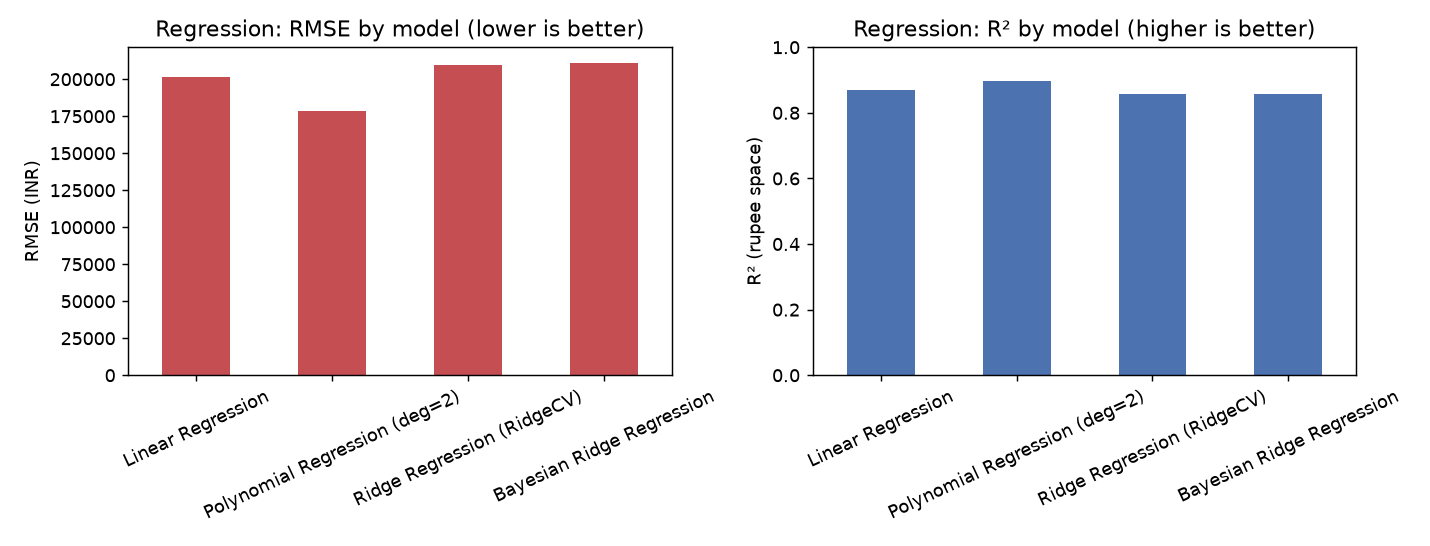

In [16]:
display(reg_results[['MAE (INR)', 'RMSE (INR)', 'R2 (rupee space)']].round(2))
display(Image(filename='outputs/figures/regression_comparison.png'))


**Observed differences.** Polynomial Regression gets the lowest RMSE and highest R²
(≈0.90) — the numeric-feature interactions/curvature it adds (e.g. price falling off
faster at very high `car_age`, or `max_power`'s effect depending on `engine` size) are real
and linear-only models can't capture them. Ridge and Bayesian Ridge score marginally *below*
plain Linear Regression here: with ~46 features on ~5,400 training rows, the dataset isn't
badly overfit to begin with, so regularisation mostly shrinks useful signal rather than removing
noise — RidgeCV's own cross-validation selected a small α, confirming little regularisation was
actually needed. Ridge and Bayesian Ridge track each other closely, as expected (they are
different estimation procedures — closed-form ℓ2-penalised vs. a Bayesian evidence-maximising
posterior mean — over essentially the same model family).

### 4.2 Classification comparison — accuracy, precision, recall, F1, confusion matrix


,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Logistic Regression,0.8214,0.8238,0.8208,0.8217
Linear SVM,0.7842,0.7790,0.7812,0.7713
RBF-Kernel SVM,0.8371,0.8379,0.8364,0.8367


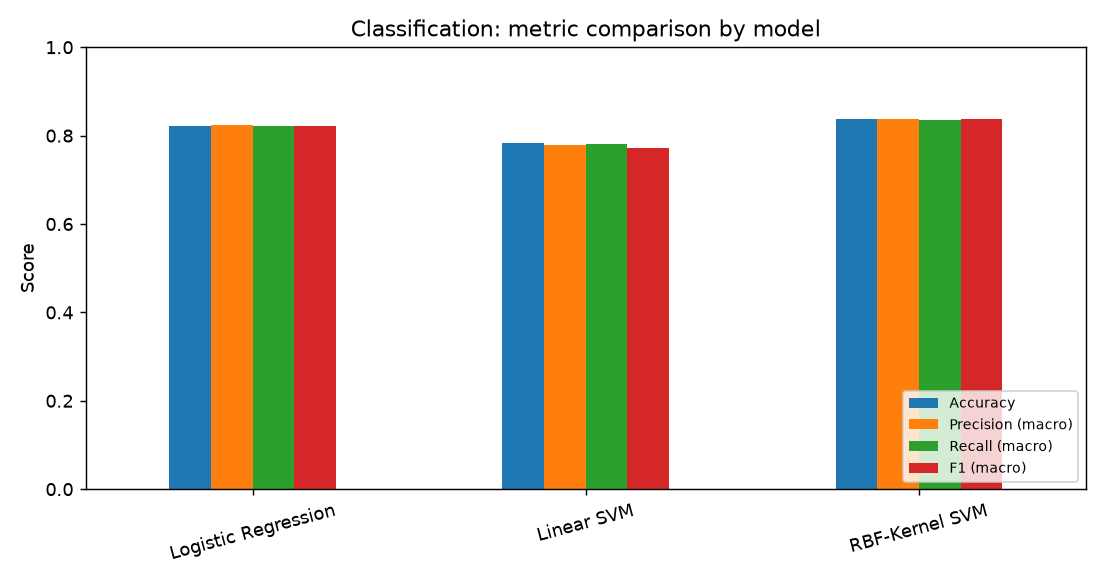

In [17]:
display(clf_results.round(4))
display(Image(filename='outputs/figures/classification_comparison.png'))


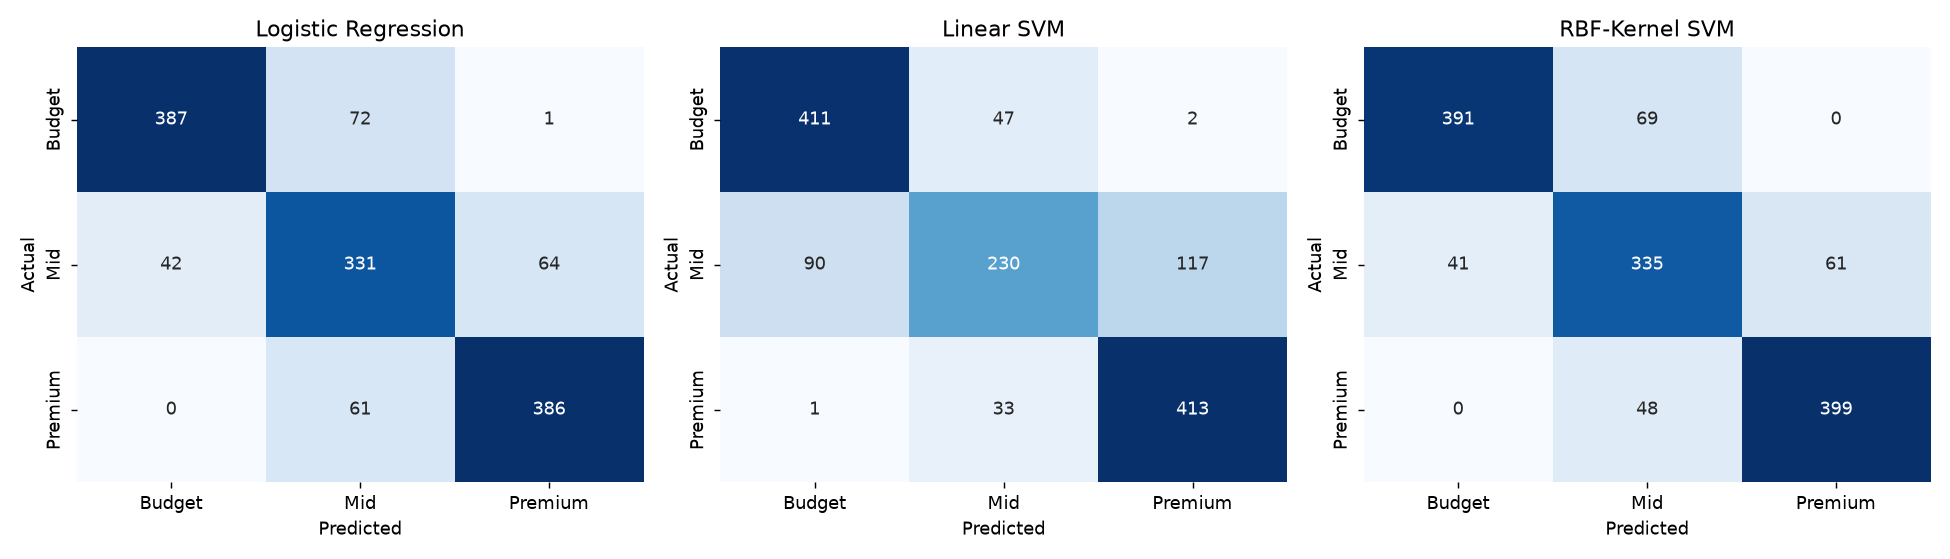

In [18]:
display(Image(filename='outputs/figures/confusion_matrices.png'))


**Observed differences.** RBF-kernel SVM edges out Logistic Regression (≈0.84 vs ≈0.82
accuracy); the linear SVM trails clearly (≈0.78). All three confusion matrices show the *same
pattern*: confusion is concentrated almost entirely between **adjacent** tiers (Budget↔Mid,
Mid↔Premium), with near-zero Budget↔Premium confusion — the tiers are ordered price bands, so
a model that is "close but on the wrong side of a cut point" naturally lands in the neighbouring
class, not the opposite end. The Mid class has the lowest per-class F1 for every model, because
it is bounded on *both* sides by a threshold (Budget and Mid share one boundary, Mid and Premium
share the other), so it absorbs the boundary error from both directions that the outer classes
only take from one side.

**Cross-task consistency.** The classifier is, by construction, a discretised version of the
regressor over the *same* feature set and the *same* split — so their relative performance is
expected to track rather than being two independent findings. Polynomial Regression's edge in
R² and RBF-SVM's edge in accuracy both come from the same source: real non-linearity in how
`car_age`/`max_power`/`engine` jointly determine price, which only the non-linear model in each
pair captures.


---
## Q5. Result Interpretation & Presentation — 4 Marks

### 5.1 What drives the prediction


,feature,coefficient,abs_coefficient
0,owner_Test Drive Car,0.653167,0.653167
1,brand_Tata,-0.631621,0.631621
2,brand_Chevrolet,-0.572007,0.572007
3,brand_Land,0.521628,0.521628
4,brand_Datsun,-0.520767,0.520767
5,brand_Force,-0.510182,0.510182
6,brand_Ashok,-0.442723,0.442723
7,car_age,-0.434761,0.434761
8,brand_Fiat,-0.424679,0.424679
9,brand_Mahindra,-0.377597,0.377597


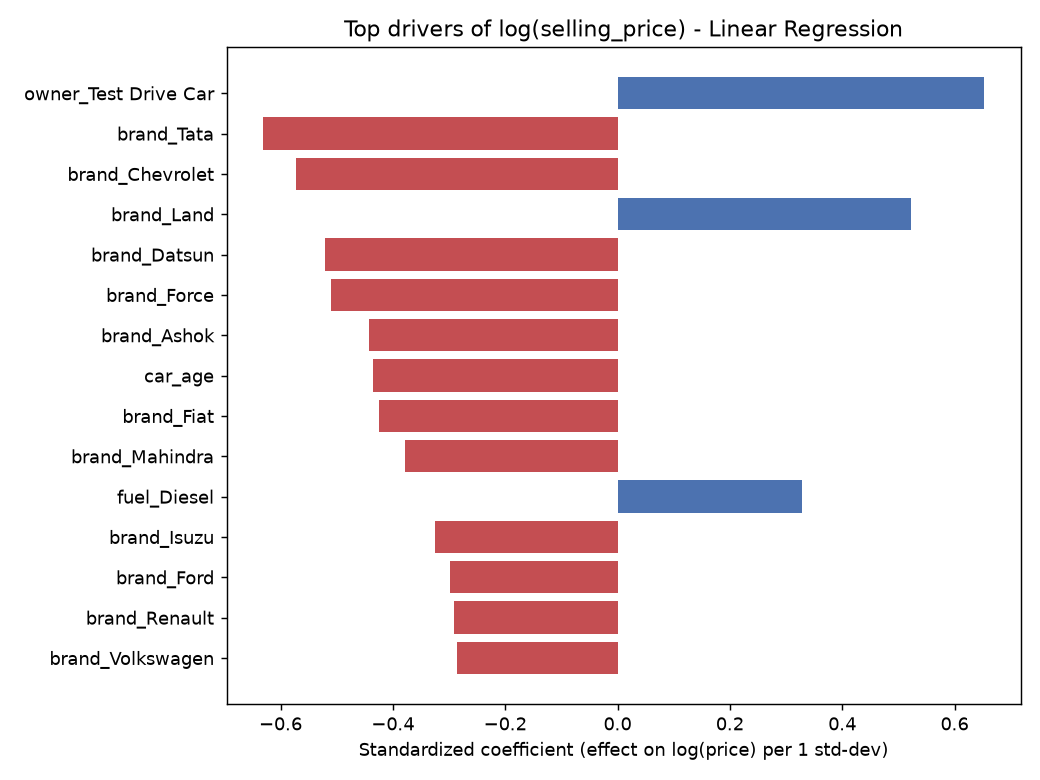

In [19]:
from interpret import linear_regression_coefficients, logistic_regression_coefficients
lin_coef = linear_regression_coefficients(reg_models)
display(lin_coef.head(10))
display(Image(filename='outputs/figures/linear_regression_top_coefficients.png'))


In [20]:
log_coef = logistic_regression_coefficients(clf_models)
display(log_coef.head(10).round(3))


,Budget,Mid,Premium
car_age,3.216,0.062,-3.278
fuel_Diesel,-2.116,-0.918,3.034
brand_Tata,1.985,0.263,-2.247
brand_Toyota,-1.811,0.135,1.676
max_power,-1.617,-0.129,1.746
brand_Chevrolet,1.328,0.151,-1.480
brand_Datsun,1.169,0.296,-1.465
brand_Honda,-1.350,0.153,1.197
brand_Maruti,-1.219,-0.003,1.223
brand_Mercedes-Benz,-0.723,-0.404,1.128


Coefficients are on **standardized** features, so they read directly as "effect per one
std-dev change in that feature" and are comparable to each other. `car_age` is the single
strongest, sign-consistent driver in both models (negative for price, and for tier: positive
weight toward Budget / negative toward Premium) — older cars are reliably worth less and more
likely to fall in the Budget tier. `brand` dummies dominate the top-10 list for price
(Tata/Chevrolet/Datsun/Force pull price down relative to the baseline brand; Land — Land Rover —
pulls it up sharply), showing brand reputation/segment carries real, separable price information
beyond the physical specs. `fuel_Diesel` and `max_power` are the next-strongest tier drivers
after brand and age — consistent with the Q2 insight that diesel/high-power cars skew premium.

### 5.2 Practical significance

A ≈INR 88–95k MAE against a median price of INR 4.2L (≈2.7% of price at RMSE ≈ INR 178–211k,
about 4.2–5% of price) is workable for a *guidance* price — narrow enough for a listing platform
to flag a quote as under/overpriced — but not tight enough to replace an inspector's appraisal
for a single high-value transaction. The classifier's ≈82–84% accuracy is strong enough for
**filtering/browsing** (a "Budget/Mid/Premium" facet on a search page) where an occasional
adjacent-tier misclassification (Budget↔Mid) is low-cost, but not for anything price-binding.

### 5.3 Limitations

- **Single market snapshot** (model years only run to 2020) — the model will drift as the used-car
  market moves and would need periodic retraining on fresh listings.
- **No accident/service history or physical inspection data** — the "condition" in this project's
  classification task is a *value* proxy (price tier) standing in for true mechanical condition,
  which the raw dataset simply does not capture. This is stated explicitly, not hidden behind the
  metric numbers.
- **`mileage` mixes two physical units** (kmpl for petrol/diesel, km/kg for CNG/LPG) merged into
  one numeric column; the `fuel` categorical feature lets the models partially compensate, but the
  raw number isn't strictly apples-to-apples across fuel types.
- **`km_driven` is capped at the 99th percentile for modelling** to stop a handful of extreme
  listings (up to 2.36M km) from dominating the fit — genuine but rare high-mileage cars are
  slightly under-weighted as a result.

### 5.4 Conclusion & future work

Both tasks confirm the same underlying structure: car age, engine output (max_power/torque/
engine size) and brand jointly explain most of the price variation, with real non-linear
interaction among them (Polynomial Regression and RBF-SVM both outperform their linear
counterparts on exactly that basis). Future work: (1) fold in an external market-index feature to
correct for the 2020 snapshot's staleness, (2) test degree-3 polynomial or a spline basis on
`car_age` specifically, since price-vs-age is visibly non-linear (steep early depreciation,
flattening later) in the Q2 scatter plot, and (3) if genuine condition data (accident history,
service records) becomes available, replace the price-tier proxy with a true condition label.
